In [12]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np
sys.path.append('../../')
from utils_plots import apply_plot_style, get_layers, load_ii_curves, linestyle_for_language
eps = 1E-7
colors, markers, _linestyles = apply_plot_style()
plot_id = 0
sys.path.append(os.path.expanduser('~/syn-sem'))
from modelpaths import get_model_depths
depths = get_model_depths()
from utils import makefolder

def load_ii_heatmap(*, base, batch_shuffle, modelA, modelB, aux_A, aux_B, n_files, min_token_length, languageA, languageB, mask, k, Nbits, seeds, n_tokens, avg_tokens, return_std=True):
    mats_ab = []
    mats_ba = []
    for seed in seeds:
        folder = makefolder(
            base=base,
            create_folder=False,
            batch_shuffle=batch_shuffle,
            modelA=modelA,
            modelB=modelB,
            aux_A=aux_A,
            aux_B=aux_B,
            n_files=n_files,
            min_token_length=min_token_length,
            languageA=languageA,
            languageB=languageB,
            mask=mask,
            k=k,
            Nbits=Nbits,
            seed=seed,
        )
        mats_ab.append(np.load(folder + f"n_tokens_{n_tokens}_avg_{avg_tokens}_AB.npy"))
        mats_ba.append(np.load(folder + f"n_tokens_{n_tokens}_avg_{avg_tokens}_BA.npy"))

    stack_ab = np.stack(mats_ab, axis=0)
    stack_ba = np.stack(mats_ba, axis=0)
    mean_ab = stack_ab.mean(axis=0)
    mean_ba = stack_ba.mean(axis=0)

    if return_std:
        ddof = 1 if len(seeds) > 1 else 0
        std_ab = stack_ab.std(axis=0, ddof=ddof)
        std_ba = stack_ba.std(axis=0, ddof=ddof)
        return mean_ab, mean_ba, std_ab, std_ba

    return mean_ab, mean_ba


In [13]:
import numpy as np
import matplotlib.pyplot as plt


modelA = 'deepseek'
_modelA ='deepseek'

# modelB = modelA
# _modelB = _modelA

modelB = "llama"
_modelB = 'llama8b'

# modelA = modelB
# _modelA = _modelB




mask = 2
language_pairs = [
    # ("german", "english"),
    ("english", "hungarian"),
    # ("english", "dutch"),
]

n_files = 200
batch_size = 10
Ns = batch_size * n_files
batch_shuffle = 0

min_token_length = 35
avg_tokens_list = [1]

k_II = 10
Nbits = 0
seeds_II = list(range(5))

n_tokens_list = [20]
n_tokens = n_tokens_list[0]

# Precompute "condition ids" so each (avg_tokens, n_tokens) gets its own color slot
valid_conditions = [
    (avg_tokens, n_tokens)
    for avg_tokens in avg_tokens_list
    for n_tokens in n_tokens_list
    if not (n_tokens == 1 and avg_tokens == 1)
]
cond_to_id = {cond: i for i, cond in enumerate(valid_conditions)}
layersA = get_layers(_modelA, depths)
xA = layersA / depths[_modelA]
layersB = get_layers(_modelB, depths)
xB = layersB / depths[_modelB]

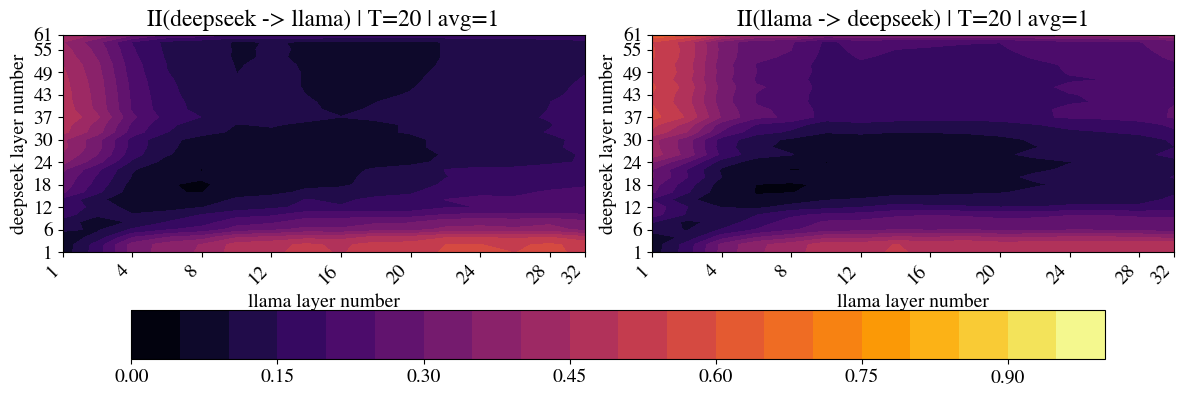

In [14]:
# -----------------------
# Heatmaps: modelA vs modelB (layer-number axes)
# -----------------------
for languageA, languageB in language_pairs:
    aux_A = "source"  # keep consistent with the DS-vs-Llama source setting
    aux_B = aux_A
    for avg_tokens in avg_tokens_list:
        for n_tokens in n_tokens_list:
            if n_tokens == 1 and avg_tokens == 1:
                continue

            II_AB, II_BA = load_ii_heatmap(
                base="../results/santiago/",
                batch_shuffle=batch_shuffle,
                modelA=modelA,
                modelB=modelB,
                aux_A=aux_A,
                aux_B=aux_B,
                n_files=n_files,
                min_token_length=min_token_length,
                languageA=languageA,
                languageB=languageB,
                mask=mask,
                k=k_II,
                Nbits=Nbits,
                seeds=seeds_II,
                n_tokens=n_tokens,
                avg_tokens=avg_tokens,
                return_std=False,
            )

            vmin = 0
            vmax = 1
            levels = np.linspace(vmin, vmax, 21)

            fig, ax = plt.subplots(1, 2, figsize=(12, 4))
            fig.tight_layout()

            im0 = ax[0].contourf(II_AB, levels=levels, cmap="inferno")
            im1 = ax[1].contourf(II_BA, levels=levels, cmap="inferno")
            fig.colorbar(im0, ax=ax, orientation="horizontal", pad=0.18)

            ax[0].set_title(f"II({modelA} -> {modelB}) | T={n_tokens} | avg={avg_tokens}")
            ax[1].set_title(f"II({modelB} -> {modelA}) | T={n_tokens} | avg={avg_tokens}")

            # Use real layer numbers (not relative depth) and thin ticks to avoid overlap.
            max_x_ticks = 12
            max_y_ticks = 10
            x_step = max(1, int(np.ceil(len(layersB) / max_x_ticks)))
            y_step = max(1, int(np.ceil(len(layersA) / max_y_ticks)))

            x_tick_idx = np.arange(0, len(layersB), x_step)
            y_tick_idx = np.arange(0, len(layersA), y_step)
            if x_tick_idx[-1] != len(layersB) - 1:
                x_tick_idx = np.append(x_tick_idx, len(layersB) - 1)
            if y_tick_idx[-1] != len(layersA) - 1:
                y_tick_idx = np.append(y_tick_idx, len(layersA) - 1)

            x_tick_labels = [str(int(layersB[i])) for i in x_tick_idx]
            y_tick_labels = [str(int(layersA[i])) for i in y_tick_idx]

            for a in ax:
                a.set_xticks(x_tick_idx)
                a.set_xticklabels(x_tick_labels, rotation=45, ha="right")
                a.set_yticks(y_tick_idx)
                a.set_yticklabels(y_tick_labels)

            ax[0].set_xlabel(f"{modelB} layer number")
            ax[1].set_xlabel(f"{modelB} layer number")
            ax[0].set_ylabel(f"{modelA} layer number")
            ax[1].set_ylabel(f"{modelA} layer number")

            plt.show()


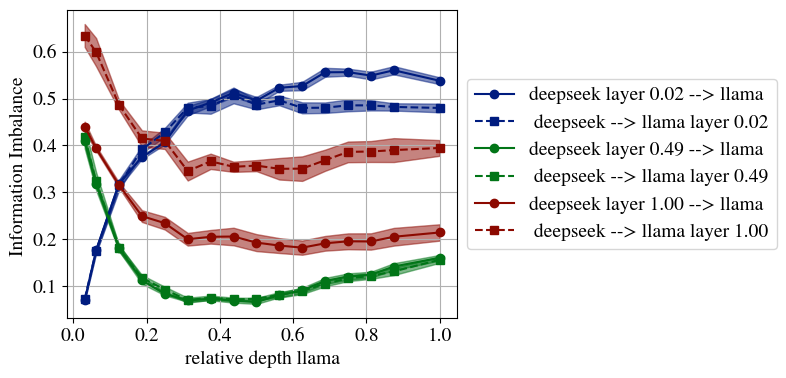

In [15]:
# -----------------------
# 1D slice: pick DS layer with smallest II vs all Llama layers (n_tokens=20)
# -----------------------
# Use first language pair by default

languageA, languageB = language_pairs[0]
aux_A = "target" if languageB == "dutch" or languageB == 'english' else "source"
aux_B = aux_A

# Choose condition for 20 tokens and first avg_tokens value
avg_tokens = avg_tokens_list[0]

II_AB, II_BA, II_AB_std, II_BA_std = load_ii_heatmap(
    base="../results/santiago/",
    batch_shuffle=batch_shuffle,
    modelA=modelA,
    modelB=modelB,
    aux_A=aux_A,
    aux_B=aux_B,
    n_files=n_files,
    min_token_length=min_token_length,
    languageA=languageA,
    languageB=languageB,
    mask=mask,
    k=k_II,
    Nbits=Nbits,
    seeds=seeds_II,
    n_tokens=n_tokens,
    avg_tokens=avg_tokens,
    return_std=True,
)

layer_ids_ds = [
                0, 
                int(len(xA)* 1/2.), 
                # int(len(xA)* 3/5.), 
                # int(len(xA)* 2/5.), 
                len(xA)-1,
                ]

fig, ax = plt.subplots(1, 1, figsize=(7, 4))
for eum_layer_id,layer_id_ds in enumerate(layer_ids_ds):
    ab_mean = II_AB[layer_id_ds, :]
    ab_std = II_AB_std[layer_id_ds, :]
    ba_mean = II_BA[layer_id_ds, :]
    ba_std = II_BA_std[layer_id_ds, :]

    ax.plot(xB, 
            ab_mean, 
            marker='o', 
            linestyle='-', 
            label=f"{modelA} layer {xA[layer_id_ds]:.2f} --> {modelB} ",
            color=colors[eum_layer_id],
            )
    ax.fill_between(xB, ab_mean - ab_std, ab_mean + ab_std,
                    color=colors[eum_layer_id], alpha=0.5)

    ax.plot(xB, 
            ba_mean, 
            marker='s', 
            linestyle='--', 
            label=f" {modelA} --> {modelB} layer {xA[layer_id_ds]:.2f}",
            color=colors[eum_layer_id],
            )
    ax.fill_between(xB, ba_mean - ba_std, ba_mean + ba_std,
                    color=colors[eum_layer_id], alpha=0.50)
    
ax.set_xlabel(f"relative depth {modelB}")
ax.set_ylabel("Information Imbalance ")
# ax.set_title(f'#samples:{Ns} | {len(seeds_II)} seeds')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.grid()
# ax.legend()
plt.show()

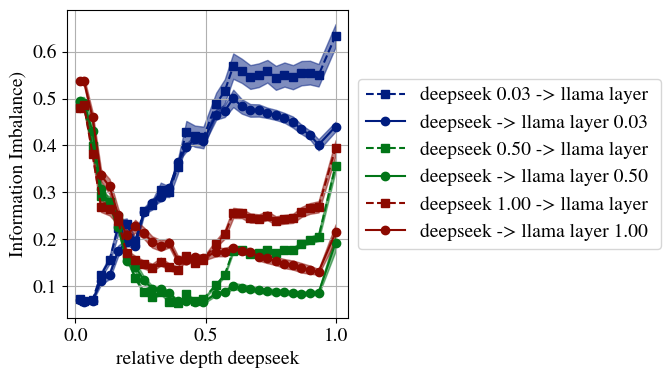

In [16]:
# -----------------------
# 1D slice: Llama -> DeepSeek with reciprocal DS -> Llama
# -----------------------
layer_ids_llama = [
      0,
      len(xB)//2, 
      len(xB)-1,
                   ]

fig, ax = plt.subplots(1, 1, figsize=(6, 4))
for eum_layer_id, layer_id_llama in enumerate(layer_ids_llama):
    ba_mean = II_BA[:, layer_id_llama]
    ba_std = II_BA_std[:, layer_id_llama]
    ab_mean = II_AB[:, layer_id_llama]
    ab_std = II_AB_std[:, layer_id_llama]

    # Llama -> DS (II_BA): sweep DS layers for fixed Llama layer
    ax.plot(
        xA,
        ba_mean,
        marker='s',
        linestyle='--',
        label=f"{modelA} {xB[layer_id_llama]:.2f} -> {modelB} layer ",
        color=colors[eum_layer_id],
    )
    ax.fill_between(xA, ba_mean - ba_std, ba_mean + ba_std,
                    color=colors[eum_layer_id], alpha=0.5)

    # DS -> Llama (II_AB): sweep DS layers for the same fixed Llama layer
    ax.plot(
        xA,
        ab_mean,
        marker='o',
        linestyle='-',
        color=colors[eum_layer_id],
        label=f"{modelA} -> {modelB} layer {xB[layer_id_llama]:.2f}",
    )
    ax.fill_between(xA, ab_mean - ab_std, ab_mean + ab_std,
                    color=colors[eum_layer_id], alpha=0.5)

ax.set_xlabel(f"relative depth {modelA}")
ax.set_ylabel("Information Imbalance)")
# ax.set_title(f'#samples:{Ns} | {len(seeds_II)} seeds')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax.grid()

# ax.legend()
plt.show()

Exported matched-depth plot to ../results/figs/ds_vs_llama_english.pdf


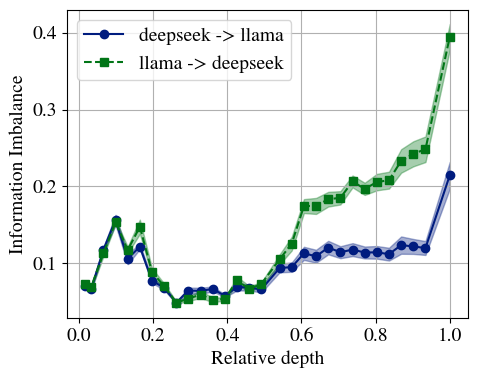

In [17]:
# -----------------------
# Relative-depth matched cross-model "diagonal": DeepSeek depth -> nearest Llama depth
# -----------------------
if modelA != modelB:
  languageA, languageB = language_pairs[0]
  aux_A = "target" if languageB == "dutch" else "source"
  aux_B = aux_A
  avg_tokens = avg_tokens_list[0]

  if "II_AB" not in globals() or "II_BA" not in globals() or "II_AB_std" not in globals() or "II_BA_std" not in globals():
      II_AB, II_BA, II_AB_std, II_BA_std = load_ii_heatmap(
          base="../results/santiago/",
          batch_shuffle=batch_shuffle,
          modelA=modelA,
          modelB=modelB,
          aux_A=aux_A,
          aux_B=aux_B,
          n_files=n_files,
          min_token_length=min_token_length,
          languageA=languageA,
          languageB=languageB,
          mask=mask,
          k=k_II,
          Nbits=Nbits,
          seeds=seeds_II,
          n_tokens=n_tokens,
          avg_tokens=avg_tokens,
          return_std=True,
      )

  # For each DeepSeek relative depth, pick the closest available Llama relative depth
  matched_llama_idx = np.abs(xB[None, :] - xA[:, None]).argmin(axis=1)
  ii_ab_matched = II_AB[np.arange(len(xA)), matched_llama_idx]
  ii_ba_matched = II_BA[np.arange(len(xA)), matched_llama_idx]
  ii_ab_matched_std = II_AB_std[np.arange(len(xA)), matched_llama_idx]
  ii_ba_matched_std = II_BA_std[np.arange(len(xA)), matched_llama_idx]

  fig_out_path = "../results/figs/ds_vs_llama_english.pdf"

  fig, ax = plt.subplots(1, 1, figsize=(5, 4))

  ax.plot(xA, ii_ab_matched, marker="o", linestyle="-", color=colors[0], label=f"{modelA} -> {modelB}")
  ax.fill_between(xA, ii_ab_matched - ii_ab_matched_std, ii_ab_matched + ii_ab_matched_std, color=colors[0], alpha=0.35)

  ax.plot(xA, ii_ba_matched, marker="s", linestyle="--", color=colors[1], label=f"{modelB} -> {modelA}")
  ax.fill_between(xA, ii_ba_matched - ii_ba_matched_std, ii_ba_matched + ii_ba_matched_std, color=colors[1], alpha=0.35)

  ax.set_xlabel(f"Relative depth")
  ax.set_ylabel("Information Imbalance")
  ax.grid(True)

#   box = ax.get_position()
#   ax.set_position([box.x0, box.y0, box.width * 0.78, box.height])
#   ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
  ax.legend()
  fig.savefig(fig_out_path, bbox_inches="tight")
  print(f"Exported matched-depth plot to {fig_out_path}")
  plt.show()


In [18]:
if modelA == modelB: 
  if "II_AB" not in globals() or "II_BA" not in globals():
      languageA, languageB = language_pairs[0]
      aux_A = "target" if languageB == "dutch" or languageB == "english" else "source"
      aux_B = aux_A
      avg_tokens = avg_tokens_list[0]

      II_AB, II_BA = load_ii_heatmap(
          base="../results/santiago/",
          batch_shuffle=batch_shuffle,
          modelA=modelA,
          modelB=modelB,
          aux_A=aux_A,
          aux_B=aux_B,
          n_files=n_files,
          min_token_length=min_token_length,
          languageA=languageA,
          languageB=languageB,
          mask=mask,
          k=k_II,
          Nbits=Nbits,
          seeds=seeds_II,
          n_tokens=n_tokens,
          avg_tokens=avg_tokens,
          return_std=False,
      )

  asym_ab_ba = II_AB - II_BA
  target_depths = np.round(np.linspace(0.0, 1.0, 5+1), 1)
  target_depths = np.round(np.array([.1,.2,.3,.4,.5,.6,.8,.9,1.]),1)
  fixed_layers = [int(np.abs(xA - d).argmin()) for d in target_depths]
  fixed_layers = sorted(set(fixed_layers))
  chosen_depths = xA[fixed_layers]


  depth_cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
      "depth3",
      ["#2A9D8F", "#E9C46A", "#D1495B"],
      N=256,
  )
  depth_norm = plt.Normalize(vmin=0.0, vmax=1.0)
  depth_colors = depth_cmap(depth_norm(chosen_depths))

  fig, ax = plt.subplots(1, 1, figsize=(7, 4))
  for i, layer_id in enumerate(fixed_layers):
      idx_end = min(layer_id, len(xB) - 1)
      x_slice = xB[: idx_end + 1]
      y_slice = asym_ab_ba[layer_id, : idx_end + 1]

      ax.plot(
          x_slice,
          y_slice,
          marker="o",
          linestyle="-",
          color=depth_colors[i],
          linewidth=1.7,
      )

  ax.axhline(0.0, color="black", linestyle="--", linewidth=1)
  ax.set_xlabel(r"$l'/L$" + f" {modelB}")
  ax.set_ylabel(r"$II(l \rightarrow l') - II(l' \rightarrow l)$")
  ax.grid(True)
  ax.set_title(modelA)
  sm = plt.cm.ScalarMappable(cmap=depth_cmap, norm=depth_norm)
  sm.set_array([])
  cbar = fig.colorbar(sm, ax=ax, pad=0.02)
  cbar.set_label(r"Relative depth $l/L$")
  cbar.set_ticks([0.0, 0.5, 1.0])
  cbar.set_ticklabels(["0.0", "0.5", "1.0"])

  plt.show()
